In [1]:
#1 Viết hàm allpass_filter(x, fs, delay_ms, a) hiện thực hóa phương trình (8).
import numpy as np
import matplotlib.pyplot as plt

def allpass_filter(x, fs, delay_ms, a):
    D = int(delay_ms *1e-3 *fs)
    y = np.zeros(len(x) + D *10)
    y[:len(x)] += (0-a)*x

    for n in range(D, len(y)):
        if n - D < len(x):
            y[n] += x[n-D] + a*y[n-D]
        else :
            y[n] =  a*y[n-D]

    return y


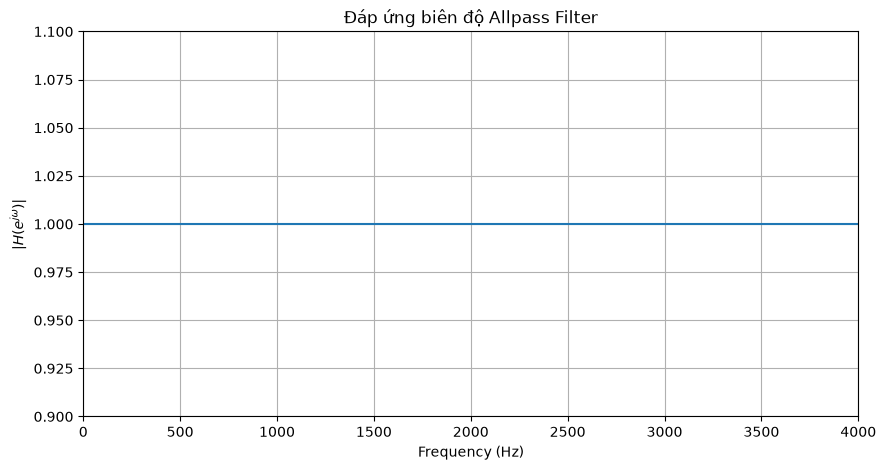

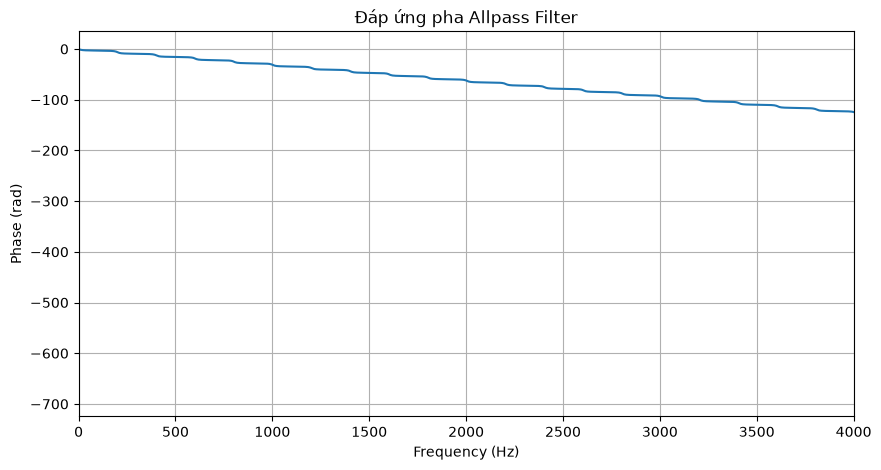

In [2]:
#Vẽ đồ thị đáp ứng biên độ |H(ejω)| và đáp ứng pha ̸ H(ejω) của bộ lọc với td = 5 ms,a = 0.7
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz

fs = 44100
td = 5
a = 0.7
D = int(td * 1e-3 * fs)

# H(z) = (z^-D - a) / (1 - a*z^-D)
b = np.zeros(D + 1)
b[0] = -a
b[D] = 1

den = np.zeros(D + 1)
den[0] = 1
den[D] = -a

f, H = freqz(b, den, worN=4096, fs=fs)

magnitude = np.abs(H)

phase = np.unwrap(np.angle(H))

plt.figure(figsize=(10, 5))
plt.plot(f, magnitude)

plt.xlabel("Frequency (Hz)")
plt.ylabel(r"$|H(e^{j\omega})|$")
plt.title("Đáp ứng biên độ Allpass Filter")
plt.xlim(0, 4000)
plt.ylim(0.9, 1.1)
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(f, phase)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (rad)")
plt.title("Đáp ứng pha Allpass Filter")
plt.xlim(0, 4000)
plt.grid()
plt.show()

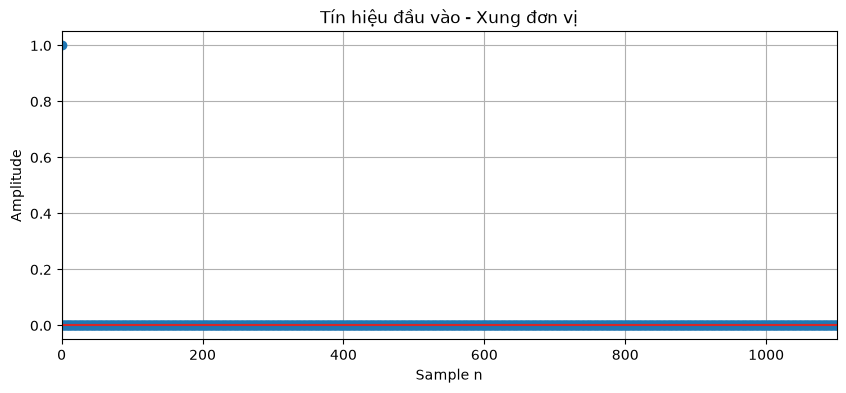

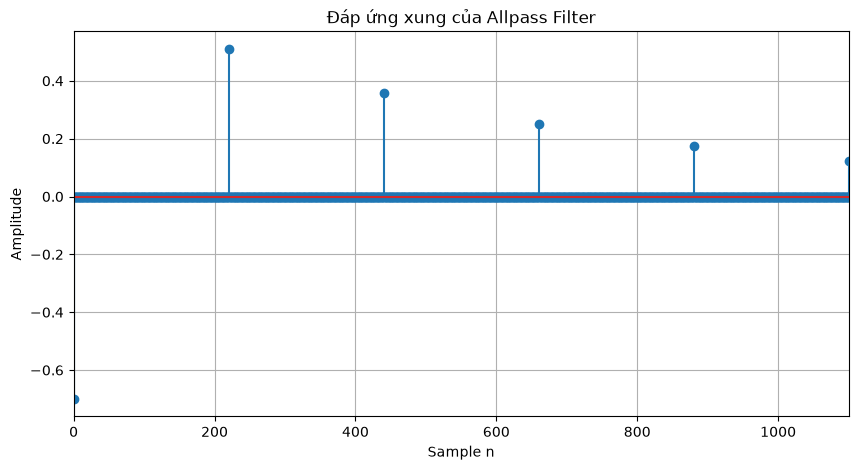

In [ ]:
#3 Cho tín hiệu đầu vào là một xung đơn vị δ[n]. Quan sát dạng sóng đầu ra
import numpy as np
import matplotlib.pyplot as plt

fs = 44100
td = 5
a = 0.7

D = int(td * 1e-3 * fs)
N = 6 * D
x = np.zeros(N)
x[0] = 1
y = allpass_filter(x, fs, td, a)
y_plot = y[:N]

plt.figure(figsize=(10, 4))
plt.stem(np.arange(N), x)

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Tín hiệu đầu vào - Xung đơn vị")
plt.xlim(0, 5 * D)
plt.grid()
plt.show()



plt.figure(figsize=(10, 5))
plt.stem(np.arange(N), y_plot)

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Đáp ứng xung của Allpass Filter")
plt.xlim(0, 5 * D)
plt.grid()
plt.show()